In [1]:
# ============================================================
# NEWS TITLE UNSUPERVISED CLUSTERING
# STEP 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================================
# STEP 2: UPLOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded file:")
for filename in uploaded.keys():
    print(filename)

Saving News_Classification_Dataset.csv to News_Classification_Dataset.csv

Uploaded file:
News_Classification_Dataset.csv


In [3]:
# ============================================================
# STEP 3: LOAD DATASET
# ============================================================

filename = list(uploaded.keys())[0]

if filename.endswith(".csv"):
    df = pd.read_csv(filename)
elif filename.endswith(".xlsx"):
    df = pd.read_excel(filename)
else:
    raise ValueError("Please upload a CSV or XLSX file.")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (5000, 4)

Columns:
['URL', 'Title', 'Category', 'Group Leader']


In [4]:
# ============================================================
# STEP 4: DATA UNDERSTANDING
# ============================================================

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nFirst 5 rows:")
display(df.head())

DATASET INFORMATION

Shape:
(5000, 4)

Columns:
['URL', 'Title', 'Category', 'Group Leader']

Data types:
URL             object
Title           object
Category        object
Group Leader    object
dtype: object

Missing values:
URL               0
Title             0
Category          1
Group Leader    735
dtype: int64

Duplicate rows:
0

First 5 rows:


,URL,Title,Category,Group Leader
0,https://asiatimes.com/2025/10/vietnam-airlines...,Vietnam Airlines data leak exposes a crisis of...,Technology,NaN
1,https://asiatimes.com/2025/10/doj-seizes-15-bi...,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets,NaN
2,https://www.fool.com/investing/2025/10/15/too-...,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets,NaN
3,https://www.fool.com/investing/2025/10/15/inte...,Intel's Crucial Panther Lake Chips Start Produ...,Technology,NaN
4,https://www.fool.com/investing/2025/10/15/3-ro...,3 Robotics Stocks to Buy in October,Markets,NaN


In [5]:
# ============================================================
# STEP 5: KEEP ONLY NEWS TITLE
# ============================================================

if "Title" not in df.columns:
    raise ValueError(
        f"'Title' column not found. Available columns: {df.columns.tolist()}"
    )

df = df[["Title"]].copy()

print("Columns after removing everything except Title:")
print(df.columns.tolist())

print("\nShape:")
print(df.shape)

display(df.head())

Columns after removing everything except Title:
['Title']

Shape:
(5000, 1)


,Title
0,Vietnam Airlines data leak exposes a crisis of...
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...
2,Think It's Too Late to Buy IonQ? Here's the 1 ...
3,Intel's Crucial Panther Lake Chips Start Produ...
4,3 Robotics Stocks to Buy in October


In [6]:
# ============================================================
# STEP 6: DATA CLEANING
# ============================================================

print("=" * 60)
print("DATA CLEANING")
print("=" * 60)

rows_before = len(df)

# Remove missing titles
df = df.dropna(subset=["Title"])

# Convert to string
df["Title"] = df["Title"].astype(str)

# Remove empty titles
df["Title"] = df["Title"].str.strip()
df = df[df["Title"] != ""]

# Remove duplicate titles
df = df.drop_duplicates(subset=["Title"])

# Clean text
def clean_title(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove punctuation/special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["Clean_Title"] = df["Title"].apply(clean_title)

# Remove titles that became empty
df = df[df["Clean_Title"] != ""]

df = df.reset_index(drop=True)

rows_after = len(df)

print(f"Rows before cleaning : {rows_before}")
print(f"Rows after cleaning  : {rows_after}")
print(f"Rows removed         : {rows_before - rows_after}")

print("\nSample cleaned titles:")
display(df[["Title", "Clean_Title"]].head(10))

DATA CLEANING
Rows before cleaning : 5000
Rows after cleaning  : 4564
Rows removed         : 436

Sample cleaned titles:


,Title,Clean_Title
0,Vietnam Airlines data leak exposes a crisis of...,vietnam airlines data leak exposes a crisis of...
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,doj seizes 15 billion bitcoin in se asia crypt...
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,think it s too late to buy ionq here s the 1 r...
3,Intel's Crucial Panther Lake Chips Start Produ...,intel s crucial panther lake chips start produ...
4,3 Robotics Stocks to Buy in October,3 robotics stocks to buy in october
5,Think It's Too Late to Buy Applied Digital? He...,think it s too late to buy applied digital her...
6,Transcript: UK Budget blues,transcript uk budget blues
7,Is Investing in Nebius Group Stock a Once-in-a...,is investing in nebius group stock a once in a...
8,What Are 3 Great Tech Stocks to Buy Right Now?,what are 3 great tech stocks to buy right now
9,"Down 27% From Its High, Is CoreWeave a Top AI ...",down 27 from its high is coreweave a top ai st...


In [7]:
# ============================================================
# STEP 7: EXPLORATORY DATA ANALYSIS
# ============================================================

df["Title_Length"] = df["Clean_Title"].str.split().str.len()

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("\nTitle length statistics:")
display(df["Title_Length"].describe())

print("\nShortest title:")
print(df.loc[df["Title_Length"].idxmin(), "Title"])

print("\nLongest title:")
print(df.loc[df["Title_Length"].idxmax(), "Title"])

print("\nAverage title length:",
      round(df["Title_Length"].mean(), 2),
      "words")

EXPLORATORY DATA ANALYSIS

Title length statistics:


,Title_Length
count,4564.000000
mean,11.992112
std,4.006014
min,1.000000
25%,9.000000
50%,12.000000
75%,14.000000
max,42.000000



Shortest title:
מגמה מעורבת בתל אביב; מדד הביטוח נופל במעל 2%

Longest title:
A group of buyers agreed to acquire Aligned Data Centers, LLC from Macquarie Infrastructure Partners V, L.P., Macquarie Infrastructure Partners IV SCSP funds managed by Macquarie Infrastructure Partners Inc., and its co-invest partners for an enterprise value of $40 billion.

Average title length: 11.99 words


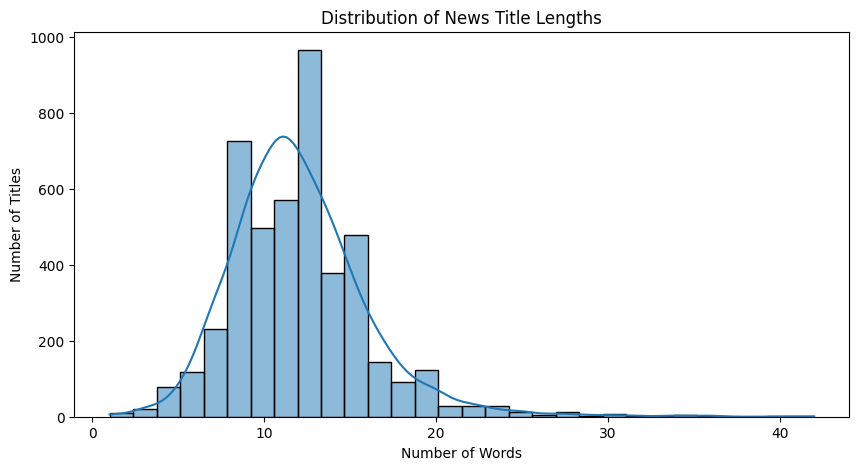

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Title_Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of News Title Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Titles")

plt.show()

In [9]:
# ============================================================
# STEP 8: TF-IDF FEATURE ENGINEERING
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("=" * 60)
print("TF-IDF FEATURE ENGINEERING")
print("=" * 60)

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=20000,
    sublinear_tf=True,
    norm="l2"
)

X_tfidf = vectorizer.fit_transform(df["Clean_Title"])

print("TF-IDF completed successfully!")

print("\nNumber of documents:", X_tfidf.shape[0])
print("Number of features:", X_tfidf.shape[1])

print("\nTF-IDF matrix shape:")
print(X_tfidf.shape)

print("\nMatrix type:")
print(type(X_tfidf))

print("\nVocabulary sample:")
print(list(vectorizer.vocabulary_.keys())[:30])

TF-IDF FEATURE ENGINEERING
TF-IDF completed successfully!

Number of documents: 4564
Number of features: 8455

TF-IDF matrix shape:
(4564, 8455)

Matrix type:
<class 'scipy.sparse._csr.csr_matrix'>

Vocabulary sample:
['vietnam', 'airlines', 'data', 'leak', 'exposes', 'crisis', 'transparency', 'doj', 'seizes', '15', 'billion', 'bitcoin', 'se', 'asia', 'crypto', 'scam', 'seizes 15', '15 billion', 'billion bitcoin', 'crypto scam', 'think', 'late', 'buy', 'reason', 'time', 'think late', 'late buy', 'reason time', 'intel', 'crucial']


In [10]:
# ============================================================
# STEP 9: TF-IDF FEATURE ANALYSIS
# ============================================================

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

# Average TF-IDF score for each feature
mean_tfidf = np.asarray(
    X_tfidf.mean(axis=0)
).flatten()

top_indices = mean_tfidf.argsort()[-30:][::-1]

top_features = pd.DataFrame({
    "Feature": feature_names[top_indices],
    "Mean_TFIDF": mean_tfidf[top_indices]
})

print("=" * 60)
print("TOP TF-IDF FEATURES")
print("=" * 60)

display(top_features)

TOP TF-IDF FEATURES


,Feature,Mean_TFIDF
0,2025,0.012944
1,ai,0.010727
2,says,0.010399
3,new,0.010087
4,announces,0.008842
5,china,0.008298
6,earnings,0.007825
7,trump,0.007553
8,quarter,0.007354
9,results,0.007022


In [11]:
# ============================================================
# STEP 10: SVD DIMENSIONALITY REDUCTION
# ============================================================

from sklearn.decomposition import TruncatedSVD

print("=" * 60)
print("SVD DIMENSIONALITY REDUCTION")
print("=" * 60)

n_components = min(100, X_tfidf.shape[1] - 1)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

X_svd = svd.fit_transform(X_tfidf)

explained_variance = svd.explained_variance_ratio_.sum()

print("Original TF-IDF shape:", X_tfidf.shape)
print("Reduced SVD shape:", X_svd.shape)

print(
    f"\nExplained variance by {n_components} components: "
    f"{explained_variance:.4f}"
)

SVD DIMENSIONALITY REDUCTION
Original TF-IDF shape: (4564, 8455)
Reduced SVD shape: (4564, 100)

Explained variance by 100 components: 0.1671


SVD DIMENSIONALITY REDUCTION
Original TF-IDF shape: (4564, 8455)
Reduced SVD shape: (4564, 100)

Explained variance by 100 components: 0.1671


In [13]:
# ============================================================
# STEP 11: FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("FEATURE SCALING")
print("=" * 60)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_svd)

print("Before scaling:")
print(X_svd.shape)

print("\nAfter scaling:")
print(X_scaled.shape)

print("\nMean of first 5 features:")
print(X_scaled[:, :5].mean(axis=0))

print("\nStandard deviation of first 5 features:")
print(X_scaled[:, :5].std(axis=0))

FEATURE SCALING
Before scaling:
(4564, 100)

After scaling:
(4564, 100)

Mean of first 5 features:
[ 9.23901028e-16  6.20553613e-16 -1.15455654e-17  8.66054234e-17
 -2.38877960e-17]

Standard deviation of first 5 features:
[1. 1. 1. 1. 1.]


In [14]:
# ============================================================
# STEP 12: K-MEANS CANDIDATE MODELS
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("=" * 60)
print("K-MEANS MODEL SEARCH")
print("=" * 60)

k_values = range(2, 11)

kmeans_results = []

for k in k_values:

    print(f"\nTraining K-Means with K={k}...")

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        labels
    )

    davies = davies_bouldin_score(
        X_scaled,
        labels
    )

    calinski = calinski_harabasz_score(
        X_scaled,
        labels
    )

    kmeans_results.append({
        "K": k,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies,
        "Calinski_Harabasz": calinski,
        "Inertia": model.inertia_
    })

    print(
        f"Silhouette={silhouette:.4f} | "
        f"DB={davies:.4f} | "
        f"CH={calinski:.2f}"
    )

kmeans_results_df = pd.DataFrame(kmeans_results)

print("\n")
display(kmeans_results_df)

K-MEANS MODEL SEARCH

Training K-Means with K=2...
Silhouette=0.0949 | DB=5.3500 | CH=40.84

Training K-Means with K=3...
Silhouette=0.0672 | DB=3.6631 | CH=41.39

Training K-Means with K=4...
Silhouette=0.0668 | DB=4.4992 | CH=42.59

Training K-Means with K=5...
Silhouette=0.0435 | DB=5.2573 | CH=41.97

Training K-Means with K=6...
Silhouette=0.0411 | DB=2.6092 | CH=40.30

Training K-Means with K=7...
Silhouette=0.0145 | DB=4.8824 | CH=40.49

Training K-Means with K=8...
Silhouette=0.0608 | DB=3.3903 | CH=42.04

Training K-Means with K=9...
Silhouette=0.0096 | DB=3.9075 | CH=40.77

Training K-Means with K=10...
Silhouette=0.1242 | DB=2.0472 | CH=40.47




,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inertia
0,2,0.094858,5.349989,40.836840,452350.772424
1,3,0.067237,3.663083,41.390227,448264.172049
2,4,0.066818,4.499218,42.591250,443959.992643
3,5,0.043478,5.257313,41.967771,440191.315398
4,6,0.041077,2.609228,40.297481,437078.833018
5,7,0.014547,4.882425,40.490731,433299.770257
6,8,0.060792,3.390267,42.038353,428709.959596
7,9,0.009552,3.907549,40.769422,425903.672202
8,10,0.124216,2.047202,40.474830,422596.590249


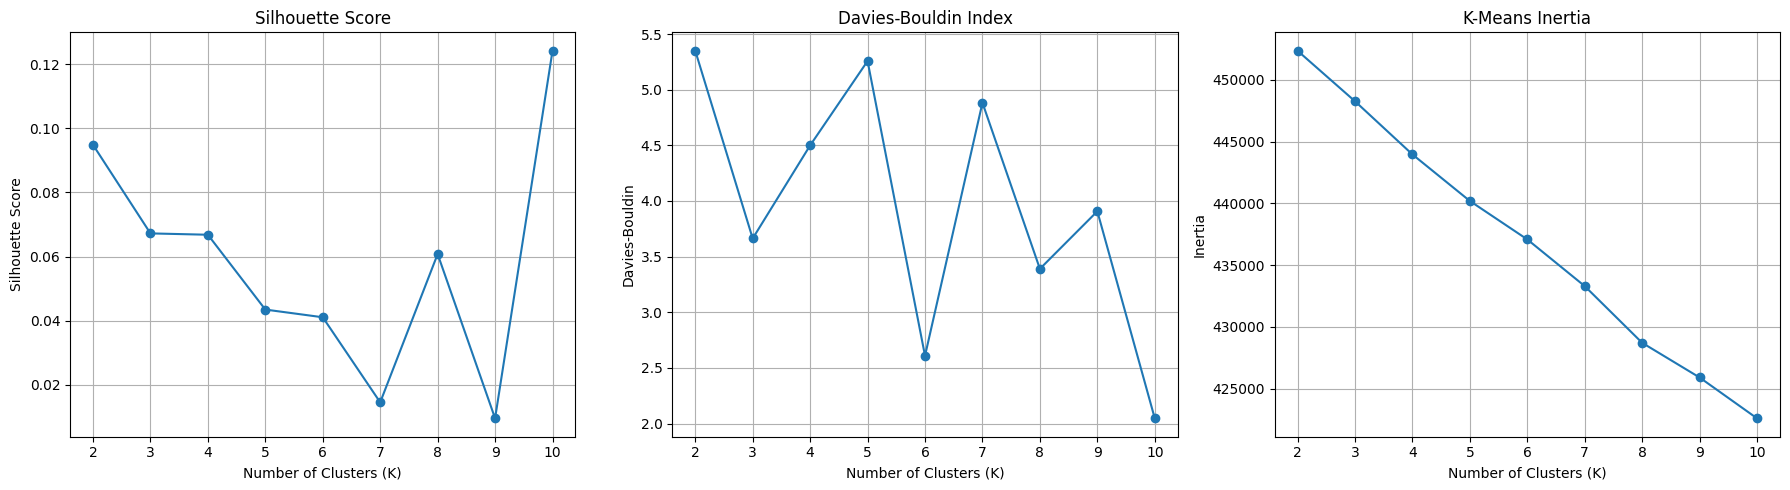

In [16]:
# ============================================================
# STEP 13: MODEL EVALUATION VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# Silhouette
axes[0].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Silhouette"],
    marker="o"
)

axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(True)


# Davies-Bouldin
axes[1].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Davies_Bouldin"],
    marker="o"
)

axes[1].set_title("Davies-Bouldin Index")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Davies-Bouldin")
axes[1].grid(True)


# Inertia
axes[2].plot(
    kmeans_results_df["K"],
    kmeans_results_df["Inertia"],
    marker="o"
)

axes[2].set_title("K-Means Inertia")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Inertia")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# STEP 14: BEST K
# ============================================================

best_k_row = kmeans_results_df.loc[
    kmeans_results_df["Silhouette"].idxmax()
]

best_k = int(best_k_row["K"])

print("=" * 60)
print("BEST K ACCORDING TO SILHOUETTE")
print("=" * 60)

print(f"\nBest K: {best_k}")

print(
    f"Silhouette Score: "
    f"{best_k_row['Silhouette']:.4f}"
)

print(
    f"Davies-Bouldin: "
    f"{best_k_row['Davies_Bouldin']:.4f}"
)

print(
    f"Calinski-Harabasz: "
    f"{best_k_row['Calinski_Harabasz']:.2f}"
)

BEST K ACCORDING TO SILHOUETTE

Best K: 10
Silhouette Score: 0.1242
Davies-Bouldin: 2.0472
Calinski-Harabasz: 40.47


In [18]:
# ============================================================
# STEP 15: FINAL K-MEANS MODEL
# ============================================================

print("=" * 60)
print("TRAINING FINAL K-MEANS MODEL")
print("=" * 60)

final_kmeans = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=20,
    max_iter=500,
    random_state=42
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

print("\nFinal model trained successfully!")

print("\nCluster distribution:")

cluster_distribution = (
    df["Cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_distribution.to_frame("Number_of_News"))

TRAINING FINAL K-MEANS MODEL

Final model trained successfully!

Cluster distribution:


,Number_of_News
Cluster,
0,4285
1,38
2,31
3,18
4,24
5,15
6,23
7,42
8,69


In [19]:
# ============================================================
# STEP 16: CLUSTER PROFILING
# ============================================================

print("=" * 60)
print("CLUSTER PROFILING")
print("=" * 60)

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

cluster_profiles = []

for cluster_id in sorted(df["Cluster"].unique()):

    indices = np.where(
        cluster_labels == cluster_id
    )[0]

    cluster_tfidf = X_tfidf[indices]

    mean_tfidf = np.asarray(
        cluster_tfidf.mean(axis=0)
    ).flatten()

    top_indices = mean_tfidf.argsort()[-15:][::-1]

    top_terms = feature_names[top_indices]

    cluster_profiles.append({
        "Cluster": cluster_id,
        "Size": len(indices),
        "Top_Terms": ", ".join(top_terms)
    })

    print(f"\nCLUSTER {cluster_id}")
    print("-" * 50)
    print("Size:", len(indices))
    print("Top terms:")
    print(", ".join(top_terms))

cluster_profiles_df = pd.DataFrame(
    cluster_profiles
)

CLUSTER PROFILING

CLUSTER 0
--------------------------------------------------
Size: 4285
Top terms:
2025, says, ai, new, china, announces, earnings, trump, quarter, results, stock, million, bank, q3, trade

CLUSTER 1
--------------------------------------------------
Size: 38
Top terms:
data talk, talk, data, ends, index, index ends, higher, settle, track, month nymex, close, fell, nymex, rises, comex

CLUSTER 2
--------------------------------------------------
Size: 31
Top terms:
center, data center, data, ai, ai data, nvidia, center deal, deal, center texas, texas, blackrock, billion, nvidia backed, blackrock nvidia, meta

CLUSTER 3
--------------------------------------------------
Size: 18
Top terms:
faruqi, behalf investors, claims behalf, investigates claims, faruqi llp, faruqi faruqi, llp investigates, behalf, llp, investigates, reminder, reminder faruqi, shareholder action, action reminder, claims

CLUSTER 4
--------------------------------------------------
Size: 24
Top ter

In [21]:
# ============================================================
# STEP 17: REPRESENTATIVE NEWS TITLES
# ============================================================

print("=" * 60)
print("REPRESENTATIVE NEWS TITLES")
print("=" * 60)

for cluster_id in sorted(df["Cluster"].unique()):

    print(f"\n{'=' * 60}")
    print(f"CLUSTER {cluster_id}")
    print(f"{'=' * 60}")

    cluster_data = df[
        df["Cluster"] == cluster_id
    ]

    for title in cluster_data["Title"].head(10):
        print("•", title)

REPRESENTATIVE NEWS TITLES

CLUSTER 0
• Vietnam Airlines data leak exposes a crisis of transparency
• DOJ seizes $15 billion bitcoin in SE Asia crypto scam bust
• Think It's Too Late to Buy IonQ? Here's the 1 Reason Why There's Still Time
• Intel's Crucial Panther Lake Chips Start Production
• 3 Robotics Stocks to Buy in October
• Think It's Too Late to Buy Applied Digital? Here's 1 Reason Why There's Still Time.
• Transcript: UK Budget blues
• Is Investing in Nebius Group Stock a Once-in-a-Lifetime Opportunity?
• What Are 3 Great Tech Stocks to Buy Right Now?
• Down 27% From Its High, Is CoreWeave a Top AI Stock to Buy Right Now?

CLUSTER 1
• EURO STOXX 50 Index Ends 0.95% Higher at 5605.03 — Data Talk
• DAX Ends 0.23% Lower at 24181.37 — Data Talk
• STOXX Europe 600 Index Ends 0.57% Higher at 567.77 — Data Talk
• Progressive Down Nearly 8%, on Track for Lowest Close Since August 2024 — Data Talk
• Bank of America on Pace for Largest Percent Increase Since April — Data Talk
• Morgan S

In [22]:
# ============================================================
# STEP 18: FINAL CLUSTER VALIDATION
# ============================================================

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("=" * 70)
print("FINAL CLUSTER VALIDATION")
print("=" * 70)

final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

final_db = davies_bouldin_score(
    X_scaled,
    cluster_labels
)

final_ch = calinski_harabasz_score(
    X_scaled,
    cluster_labels
)

print(f"\nNumber of clusters      : {best_k}")
print(f"Silhouette Score        : {final_silhouette:.4f}")
print(f"Davies-Bouldin Index    : {final_db:.4f}")
print(f"Calinski-Harabasz Score : {final_ch:.2f}")

FINAL CLUSTER VALIDATION

Number of clusters      : 10
Silhouette Score        : 0.0697
Davies-Bouldin Index    : 1.4695
Calinski-Harabasz Score : 41.19


2D CLUSTER VISUALIZATION
2D representation: (4564, 2)


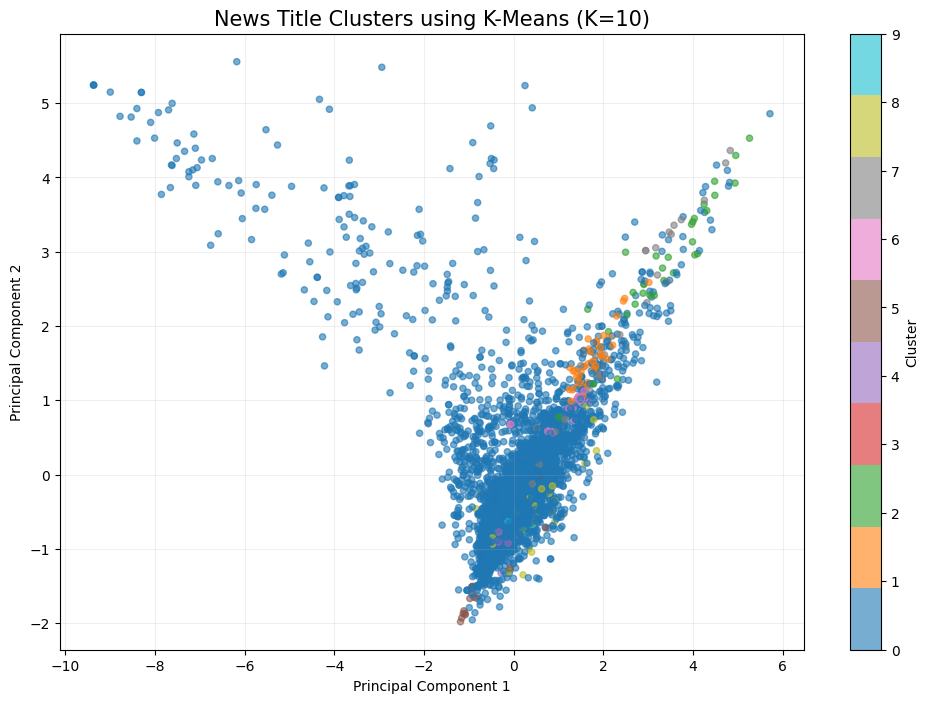

In [23]:
# ============================================================
# STEP 19: 2D CLUSTER VISUALIZATION
# ============================================================

from sklearn.decomposition import PCA

print("=" * 70)
print("2D CLUSTER VISUALIZATION")
print("=" * 70)

pca = PCA(
    n_components=2,
    random_state=42
)

X_2d = pca.fit_transform(X_scaled)

print("2D representation:", X_2d.shape)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=20,
    alpha=0.6
)

plt.title(
    f"News Title Clusters using K-Means (K={best_k})",
    fontsize=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.grid(alpha=0.2)
plt.show()

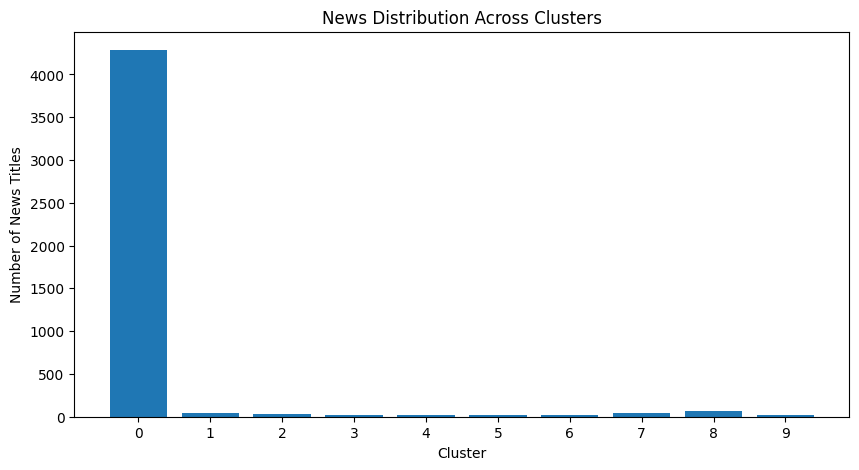


Cluster distribution:


,Number_of_Titles
Cluster,
0,4285
1,38
2,31
3,18
4,24
5,15
6,23
7,42
8,69


In [24]:
# ============================================================
# STEP 20: CLUSTER SIZE ANALYSIS
# ============================================================

cluster_counts = (
    df["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("News Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of News Titles")

plt.show()

print("\nCluster distribution:")
display(
    cluster_counts.to_frame(
        "Number_of_Titles"
    )
)

In [25]:
# ============================================================
# STEP 21: FINAL CLUSTER REPORT
# ============================================================

print("=" * 70)
print("FINAL CLUSTER REPORT")
print("=" * 70)

total_titles = len(df)

cluster_report = []

for cluster_id in sorted(df["Cluster"].unique()):

    cluster_data = df[
        df["Cluster"] == cluster_id
    ]

    size = len(cluster_data)

    percentage = (
        size / total_titles
    ) * 100

    # Get top TF-IDF terms
    indices = np.where(
        cluster_labels == cluster_id
    )[0]

    cluster_tfidf = X_tfidf[indices]

    mean_tfidf = np.asarray(
        cluster_tfidf.mean(axis=0)
    ).flatten()

    top_indices = mean_tfidf.argsort()[-15:][::-1]

    top_terms = feature_names[top_indices]

    examples = cluster_data["Title"].head(5).tolist()

    cluster_report.append({
        "Cluster": cluster_id,
        "Size": size,
        "Percentage": round(percentage, 2),
        "Top_Terms": ", ".join(top_terms),
        "Example_1": examples[0] if len(examples) > 0 else "",
        "Example_2": examples[1] if len(examples) > 1 else "",
        "Example_3": examples[2] if len(examples) > 2 else "",
        "Example_4": examples[3] if len(examples) > 3 else "",
        "Example_5": examples[4] if len(examples) > 4 else ""
    })

cluster_report_df = pd.DataFrame(
    cluster_report
)

display(cluster_report_df)

FINAL CLUSTER REPORT


,Cluster,Size,Percentage,Top_Terms,Example_1,Example_2,Example_3,Example_4,Example_5
0,0,4285,93.89,"2025, says, ai, new, china, announces, earning...",Vietnam Airlines data leak exposes a crisis of...,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Think It's Too Late to Buy IonQ? Here's the 1 ...,Intel's Crucial Panther Lake Chips Start Produ...,3 Robotics Stocks to Buy in October
1,1,38,0.83,"data talk, talk, data, ends, index, index ends...",EURO STOXX 50 Index Ends 0.95% Higher at 5605....,DAX Ends 0.23% Lower at 24181.37 — Data Talk,STOXX Europe 600 Index Ends 0.57% Higher at 56...,"Progressive Down Nearly 8%, on Track for Lowes...",Bank of America on Pace for Largest Percent In...
2,2,31,0.68,"center, data center, data, ai, ai data, nvidia...","BlackRock, Nvidia-backed group strikes $40 bil...","BlackRock, Nvidia-backed group strikes $40 bil...","BlackRock, Nvidia-backed group strikes $40 bil...","BlackRock, Nvidia-backed group strikes US$40 b...","Nvidia, BlackRock part of group acquiring data..."
3,3,18,0.39,"faruqi, behalf investors, claims behalf, inves...",TVRD SHAREHOLDER INVESTIGATION: Faruqi & Faruq...,JSPR SHAREHOLDER ACTION REMINDER: Faruqi & Far...,"SHAREHOLDER ACTION REMINDER: Faruqi & Faruqi, ...",CYTK SHAREHOLDER ACTION REMINDER: Faruqi & Far...,ATYR SHAREHOLDER ACTION REMINDER: Faruqi & Far...
4,4,24,0.53,"private placement, placement, private, non bro...",EnviroGold Increases Size of Previously Announ...,3E Network amends $7.4M private placement term...,EnviroGold increases size of private placement...,Largo Brief: Also Announces Reliance on Financ...,Largo Announces Pricing of US$23.4 Registered ...
5,5,15,0.33,"supreme court, supreme, court, voting, rights ...",Alex Jones’ $1.4 Billion Defamation Loss Stand...,Will the Voting Rights Act Be Gutted? Supreme ...,Supreme Court weighs whether to gut key provis...,Supreme Court Hearing Major Voting Case Today—...,Supreme Court probes whether Black voting righ...
6,6,23,0.50,"asset value, net asset, value, asset, net, reg...",BlackRock Throgmorton Trust Plc - Net Asset Va...,REG - HendersonFarE IncLtd - Net Asset Value(s),REG - HSBC ETFs FTSE 100 £ - Net Asset Value(s),REG - HSBC ETFs S&P500 $ - Net Asset Value(s),REG - HSBC ETFs FTSE ACC$ - Net Asset Value(s)
7,7,42,0.92,"dow, dow jones, jones, data centers, aligned d...",DJI: Dow Jones Pops in Rare 800-Point Rebound ...,"BlackRock, Nvidia-backed AI consortium to buy ...",Macquarie Group Says Macquarie Asset Managemen...,"AI Infrastructure Partnership (AIP), MGX, and ...",Dow Jones Top Company Headlines at 7 AM ET: Sa...
8,8,69,1.51,"ceo, ceo says, says, wajax, process, ai, ceo s...",Eli Lilly eyes 2027 approval for new obesity d...,Indonesia's Arsari eyes mining asset in Canada...,Wajax announces CEO succession process,Wajax Brief: Domagalski Will Continue to Serve...,Wajax Brief: Board of Directors and Iggy Domag...
9,9,19,0.42,"pro, m5, apple, chip, m5 chip, ipad, macbook, ...",Apple unveils new 14-inch MacBook Pro powered ...,Apple Introduces the Powerful New iPad Pro wit...,"Apple Updates iPad Pro, MacBook Pro, Vision Pr...","Apple announces a MacBook Pro, iPad Pro, and V...",Apple rolls out devices with more powerful M5 ...


In [26]:
# ============================================================
# STEP 22: HUMAN-READABLE CLUSTER NAMES
# ============================================================

# IMPORTANT:
# Change these names after inspecting cluster_report_df.

cluster_names = {
    cluster_id: f"Topic_{cluster_id}"
    for cluster_id in sorted(df["Cluster"].unique())
}

# Example:
# cluster_names = {
#     0: "Financial Markets",
#     1: "Politics",
#     2: "Technology",
#     3: "Business",
#     4: "Energy"
# }

df["Cluster_Name"] = df["Cluster"].map(cluster_names)

print("Cluster names assigned.")

display(
    df[
        [
            "Title",
            "Cluster",
            "Cluster_Name"
        ]
    ].head(20)
)

Cluster names assigned.


,Title,Cluster,Cluster_Name
0,Vietnam Airlines data leak exposes a crisis of...,0,Topic_0
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,0,Topic_0
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,0,Topic_0
3,Intel's Crucial Panther Lake Chips Start Produ...,0,Topic_0
4,3 Robotics Stocks to Buy in October,0,Topic_0
5,Think It's Too Late to Buy Applied Digital? He...,0,Topic_0
6,Transcript: UK Budget blues,0,Topic_0
7,Is Investing in Nebius Group Stock a Once-in-a...,0,Topic_0
8,What Are 3 Great Tech Stocks to Buy Right Now?,0,Topic_0
9,"Down 27% From Its High, Is CoreWeave a Top AI ...",0,Topic_0


In [27]:
# ============================================================
# STEP 23: SAVE CLUSTERED DATASET
# ============================================================

import os

OUTPUT_DIR = "/content/news_clustering_outputs"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Save final clustered dataset
clustered_path = os.path.join(
    OUTPUT_DIR,
    "news_clustered.csv"
)

df[
    [
        "Title",
        "Clean_Title",
        "Cluster",
        "Cluster_Name"
    ]
].to_csv(
    clustered_path,
    index=False
)

print("Clustered dataset saved:")
print(clustered_path)

Clustered dataset saved:
/content/news_clustering_outputs/news_clustered.csv


In [28]:
# ============================================================
# STEP 24: SAVE EVALUATION RESULTS
# ============================================================

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score",
        "Number of News Titles",
        "TF-IDF Features",
        "SVD Features"
    ],
    "Value": [
        best_k,
        final_silhouette,
        final_db,
        final_ch,
        len(df),
        X_tfidf.shape[1],
        X_svd.shape[1]
    ]
})

evaluation_path = os.path.join(
    OUTPUT_DIR,
    "evaluation_summary.csv"
)

evaluation_summary.to_csv(
    evaluation_path,
    index=False
)

print("Evaluation results saved.")

display(evaluation_summary)

Evaluation results saved.


,Metric,Value
0,Number of Clusters,10.000000
1,Silhouette Score,0.069690
2,Davies-Bouldin Index,1.469454
3,Calinski-Harabasz Score,41.194444
4,Number of News Titles,4564.000000
5,TF-IDF Features,8455.000000
6,SVD Features,100.000000


In [29]:
# ============================================================
# STEP 25: SAVE CLUSTER PROFILES
# ============================================================

profile_path = os.path.join(
    OUTPUT_DIR,
    "cluster_profiles.csv"
)

cluster_report_df.to_csv(
    profile_path,
    index=False
)

print("Cluster profiles saved:")
print(profile_path)

Cluster profiles saved:
/content/news_clustering_outputs/cluster_profiles.csv


In [31]:
# ============================================================
# STEP 26: SAVE ML COMPONENTS
# ============================================================

import joblib

# Save TF-IDF vectorizer
joblib.dump(
    vectorizer,
    os.path.join(
        OUTPUT_DIR,
        "tfidf_vectorizer.pkl"
    )
)

# Save SVD
joblib.dump(
    svd,
    os.path.join(
        OUTPUT_DIR,
        "svd.pkl"
    )
)

# Save scaler
joblib.dump(
    scaler,
    os.path.join(
        OUTPUT_DIR,
        "scaler.pkl"
    )
)

# Save K-Means model
joblib.dump(
    final_kmeans,
    os.path.join(
        OUTPUT_DIR,
        "kmeans_model.pkl"
    )
)

# Save cluster names
joblib.dump(
    cluster_names,
    os.path.join(
        OUTPUT_DIR,
        "cluster_names.pkl"
    )
)

print("All ML components saved successfully!")

All ML components saved successfully!


In [33]:
# ============================================================
# STEP 27: DEPLOYMENT / NEW TITLE PREDICTION
# ============================================================

def predict_news_cluster(title):

    # Clean title
    clean = clean_title(title)

    # TF-IDF
    tfidf_vector = vectorizer.transform([clean])

    # SVD
    svd_vector = svd.transform(tfidf_vector)

    # Scaling
    scaled_vector = scaler.transform(svd_vector)

    # Cluster prediction
    cluster = final_kmeans.predict(
        scaled_vector
    )[0]

    # Human-readable name
    cluster_name = cluster_names.get(
        cluster,
        f"Topic_{cluster}"
    )

    return cluster, cluster_name


# Test prediction
test_title = (
    "Federal Reserve signals another interest rate increase"
)

cluster, cluster_name = predict_news_cluster(
    test_title
)

print("News title:")
print(test_title)

print("\nPredicted cluster:", cluster)
print("Predicted topic:", cluster_name)

News title:
Federal Reserve signals another interest rate increase

Predicted cluster: 0
Predicted topic: Topic_0


In [35]:
# ============================================================
# STEP 28: TEST DEPLOYMENT
# ============================================================

new_titles = [
    "Stock markets rise as investors react to inflation data",
    "Microsoft announces new artificial intelligence technology",
    "Government announces new economic policy",
    "Oil prices increase amid global supply concerns",
    "The Oil prices may go high by two decaseds"
]

for title in new_titles:

    cluster, topic = predict_news_cluster(title)

    print("\nTitle:")
    print(title)

    print(
        f"Cluster: {cluster} | Topic: {topic}"
    )


Title:
Stock markets rise as investors react to inflation data
Cluster: 0 | Topic: Topic_0

Title:
Microsoft announces new artificial intelligence technology
Cluster: 0 | Topic: Topic_0

Title:
Government announces new economic policy
Cluster: 0 | Topic: Topic_0

Title:
Oil prices increase amid global supply concerns
Cluster: 0 | Topic: Topic_0

Title:
The Oil prices may go high by two decaseds
Cluster: 0 | Topic: Topic_0


In [36]:
# ============================================================
# STEP 29: PACKAGE PROJECT OUTPUTS
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "/content/news_clustering_project",
    "zip",
    OUTPUT_DIR
)

print("Project packaged successfully!")
print(zip_path)

Project packaged successfully!
/content/news_clustering_project.zip


In [37]:
from google.colab import files

# Download the zipped project
files.download("/content/news_clustering_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>